In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    SimpleRNN,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


In [2]:
# PARAMETERS


VOCAB_SIZE = 10000
MAX_LEN = 200
EMBEDDING_DIM = 64
BATCH_SIZE = 64
EPOCHS = 15


In [3]:
# LOAD DATASET


print("\nLoading IMDb Dataset...")

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("Training Samples:", len(X_train))
print("Testing Samples :", len(X_test))


Loading IMDb Dataset...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Samples: 25000
Testing Samples : 25000


In [4]:
# PAD SEQUENCES


X_train = pad_sequences(
    X_train,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

print("\nAfter Padding")
print("X_train Shape:", X_train.shape)
print("X_test Shape :", X_test.shape)


After Padding
X_train Shape: (25000, 200)
X_test Shape : (25000, 200)


In [5]:
# BUILD MODEL


model = Sequential([

    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        input_length=MAX_LEN
    ),

    SimpleRNN(
        64,
        return_sequences=True
    ),

    Dropout(0.3),

    SimpleRNN(
        32
    ),

    Dropout(0.3),

    Dense(
        32,
        activation='relu'
    ),

    Dense(
        1,
        activation='sigmoid'
    )
])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [6]:
# COMPILE MODEL


model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("\nModel Summary")
model.summary()


Model Summary


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
# EARLY STOPPING


early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True
)

In [8]:
# TRAIN MODEL


print("\nTraining Model...")

history = model.fit(
    X_train,
    y_train,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)


Training Model...
Epoch 1/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - accuracy: 0.4977 - loss: 0.7014 - val_accuracy: 0.5124 - val_loss: 0.6930
Epoch 2/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.4944 - loss: 0.6967 - val_accuracy: 0.5124 - val_loss: 0.6932
Epoch 3/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.5071 - loss: 0.6947 - val_accuracy: 0.4976 - val_loss: 0.6931
Epoch 4/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.5060 - loss: 0.6938 - val_accuracy: 0.5072 - val_loss: 0.6930


In [9]:
# EVALUATE MODEL


print("\nEvaluating Model...")

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"\nTest Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")



Evaluating Model...

Test Loss     : 0.6940
Test Accuracy : 0.5000


In [10]:
# PREDICTIONS


y_prob = model.predict(X_test, verbose=0)

y_pred = (y_prob > 0.5).astype(int)

In [11]:
# CLASSIFICATION REPORT


print("\nClassification Report")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)


Classification Report
              precision    recall  f1-score   support

    Negative       0.50      1.00      0.67     12500
    Positive       0.00      0.00      0.00     12500

    accuracy                           0.50     25000
   macro avg       0.25      0.50      0.33     25000
weighted avg       0.25      0.50      0.33     25000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


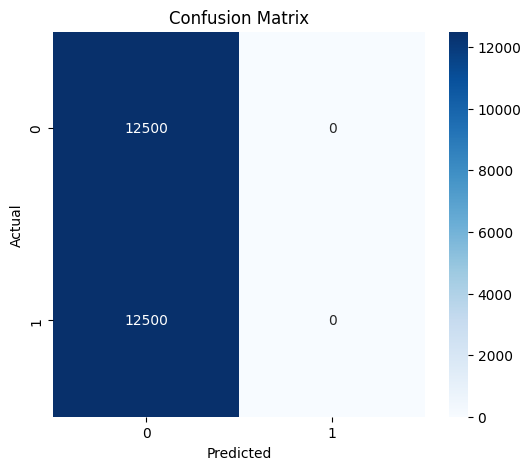

In [12]:
# CONFUSION MATRIX


cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


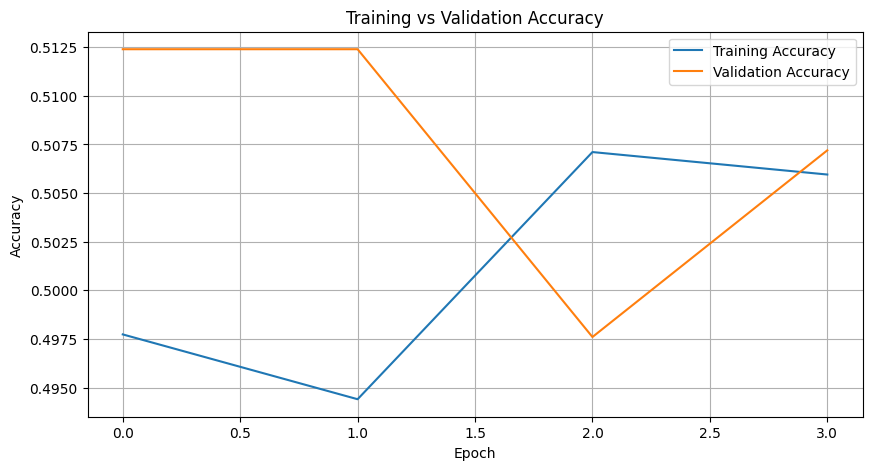

In [13]:
# TRAINING CURVES


plt.figure(figsize=(10,5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


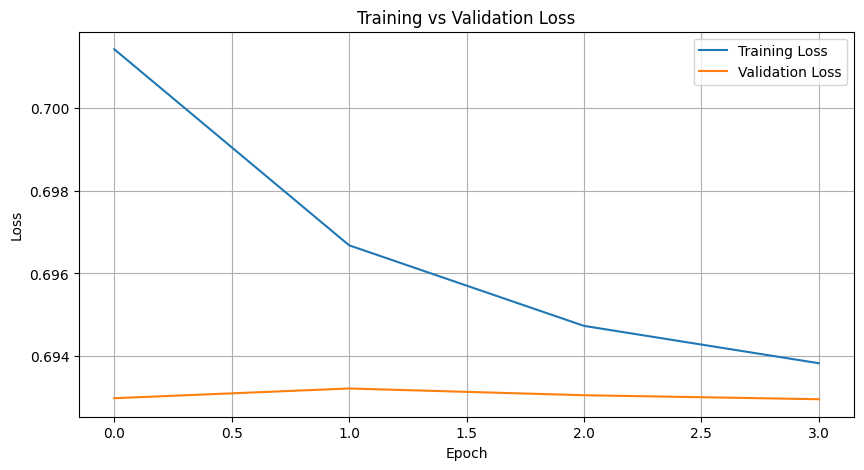

In [14]:
# LOSS CURVE


plt.figure(figsize=(10,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# MAX_LEN ABLATION STUDY


print("\n")
print("="*60)
print("MAX_LEN ABLATION STUDY")
print("="*60)

sequence_lengths = [50, 100, 150, 200]

ablation_results = []

for current_len in sequence_lengths:

    print(f"\nRunning Experiment: MAX_LEN = {current_len}")

    # Reload dataset
    (X_train, y_train), (X_test, y_test) = imdb.load_data(
        num_words=VOCAB_SIZE
    )

    X_train = pad_sequences(
        X_train,
        maxlen=current_len,
        padding='post',
        truncating='post'
    )

    X_test = pad_sequences(
        X_test,
        maxlen=current_len,
        padding='post',
        truncating='post'
    )

    model = Sequential([

        Embedding(
            VOCAB_SIZE,
            EMBEDDING_DIM,
            input_length=current_len
        ),

        SimpleRNN(
            64,
            return_sequences=True
        ),

        Dropout(0.3),

        SimpleRNN(
            32
        ),

        Dropout(0.3),

        Dense(
            32,
            activation='relu'
        ),

        Dense(
            1,
            activation='sigmoid'
        )
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        restore_best_weights=True
    )

    model.fit(
        X_train,
        y_train,
        validation_split=0.1,
        epochs=10,
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )

    loss, acc = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    ablation_results.append(acc)

    print(
        f"MAX_LEN = {current_len} "
        f"| Accuracy = {acc*100:.2f}%"
    )



MAX_LEN ABLATION STUDY

Running Experiment: MAX_LEN = 50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


MAX_LEN = 50 | Accuracy = 74.34%

Running Experiment: MAX_LEN = 100
MAX_LEN = 100 | Accuracy = 50.30%

Running Experiment: MAX_LEN = 150
MAX_LEN = 150 | Accuracy = 51.06%

Running Experiment: MAX_LEN = 200
MAX_LEN = 200 | Accuracy = 50.00%


In [16]:
# RESULTS TABLE


print("\n")
print("Ablation Study Results")
print("-"*40)

for length, acc in zip(
    sequence_lengths,
    ablation_results
):
    print(
        f"MAX_LEN = {length:<3} "
        f"Accuracy = {acc*100:.2f}%"
    )



Ablation Study Results
----------------------------------------
MAX_LEN = 50  Accuracy = 74.34%
MAX_LEN = 100 Accuracy = 50.30%
MAX_LEN = 150 Accuracy = 51.06%
MAX_LEN = 200 Accuracy = 50.00%


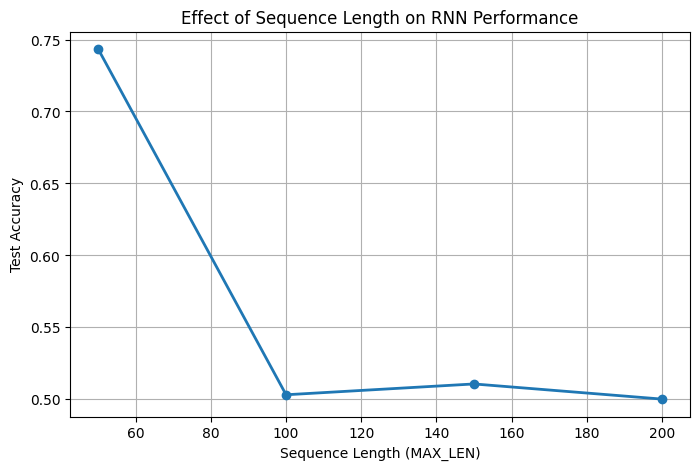

In [17]:
# PLOT ABLATION RESULTS


plt.figure(figsize=(8,5))

plt.plot(
    sequence_lengths,
    ablation_results,
    marker='o',
    linewidth=2
)

plt.xlabel("Sequence Length (MAX_LEN)")
plt.ylabel("Test Accuracy")

plt.title(
    "Effect of Sequence Length on RNN Performance"
)

plt.grid(True)
plt.show()


In [18]:
# FINAL SUMMARY


best_idx = np.argmax(ablation_results)

print("\n")
print("="*60)
print("FINAL SUMMARY")
print("="*60)

print(
    f"Best MAX_LEN = "
    f"{sequence_lengths[best_idx]}"
)

print(
    f"Best Accuracy = "
    f"{ablation_results[best_idx]*100:.2f}%"
)



FINAL SUMMARY
Best MAX_LEN = 50
Best Accuracy = 74.34%
